In [21]:
import csv
import numpy as np
import pandas as pd
from collections import Counter

In [53]:
cigar_dict = {}

snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.gaf'
snakemake_output = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01_pd.tsv'

with open(snakemake_input, "r") as infile:
    for line in infile:
        data = line.split("\t")
        ##changed to include whole readname, whitespace replaced with underscore
        read_id = data[0]#.replace(" ", "_")
        if ">" in data[5]:
            cigar_dict[read_id] = (
                "+",
                int(data[7]),
                int(data[8]),
                data[5],
                data[15].split(":")[-1][:-1],
            )
        else:
            cigar_dict[read_id] = (
                "-",
                int(data[7]),
                int(data[8]),
                data[5],
                data[15].split(":")[-1][:-1],
            )
keys_cig = list(cigar_dict.keys())

In [70]:
# snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.gaf'
# snakemake_output = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01_pd.tsv'

snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.gaf'
snakemake_output = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02_pd.tsv'

In [71]:
col_names = ['Query_name',
          'Query_length',
          'Query_start',
          'Query_end',
          'Strand',
          'Path_matching',
          'Path_length',
          'Start',
          'End',
          'Number_of_residue_matches',
          'Alignment_block_length',
          'Mapping_quality',
          '12',
          '13',
          '14',
          '15',
          '16']

In [72]:
def get_barcode(barcode_list):
    return "".join(np.array(['ON' in element for element in barcode_list if 'BIT' in element], dtype=int).astype(str))

In [73]:
df = (pd.read_csv(snakemake_input,
                  sep='\t',
                  names = col_names,
                  header = None,
                  usecols=['Query name', 'Strand', 'Path matching', 'Start', 'End', '15'])
      .drop_duplicates(subset = 'Query name', keep = False) # This is to discard "chimeric" reads. Maybe they can be handled?
     )

df = df[(df['Path matching'].str.contains('SPACER2')) & (df['Path matching'].str.contains('Variant'))] # Only keep complete reads (From variant to spacer 2)

df.loc[:, 'Query name'] = df.loc[:, 'Query name'].str.replace(' ', '_') # Remove space from Query name

df.loc[:, '15'] = df.loc[:, '15'].str.split(':').str[-1].astype(float) # Reformat column 15 (WHAT IS THIS?)

df.loc[df['Path matching'].str.contains('<'),'Strand'] = '-' # Set strand according to path matching

df.loc[df['Strand'] == '+', 'Barcode_list'] = df.loc[df['Strand'] == '+','Path matching'].str.split('>') # Get barcode list
df.loc[df['Strand'] == '-', 'Barcode_list'] = df.loc[df['Strand'] == '-','Path matching'].str.split('<').str[::-1] # Get barcode list

df['Barcode'] = df['Barcode_list'].apply(get_barcode) # Get the barcode as sequence of 0s and 1s

df = df.loc[:, ['Query name', 'Barcode', 'Strand', 'Start', 'End', 'Path matching', '15']] # Rearrange to match order of dictionary

df.to_csv(snakemake_output,
          sep='\t',
          index = False)

In [64]:
barcode_dict = {}
for key in cigar_dict.keys():
    cigar = cigar_dict[key]
    if "Variant" in cigar[3] and "SPACER2" in cigar[3]:
        if cigar[0] == "-":
            barcode = cigar[3].split("<")
            barcode = barcode[::-1]
        elif cigar[0] == "+":
            barcode = cigar[3].split(">")
        barcode = barcode[:-1]
        barcode = (
            np.array(["ON" in item for item in barcode if "BIT" in item])
            .astype(int)
            .astype(str)
            .tolist()
        )
        barcode = "".join(barcode)
        barcode_dict[key] = barcode

# Set threshold

In [181]:
snakemake_input_1 = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv'
snakemake_input_2 = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.tsv'
inpathlist = [snakemake_input_1, snakemake_input_2]

df = pd.concat((pd.read_csv(filename, sep = '\t', usecols=['Query_name', 'Barcode']) for filename in inpathlist), ignore_index = True)
assert len(df) == len(df['Query_name'].unique()) # Read names are unique after concatenating dataframes

In [182]:
d

,Query_name,Barcode
0,145454e5-ef8a-4b33-91af-994234a15b93_LP5HKG_01,000011100100001101000010110001
1,ca655e0a-e4bb-462c-9ced-b35de0d1d253_LP5HKG_01,111001010001101000101101110010
2,4da02c64-a839-414c-b112-0ea0c381b2af_LP5HKG_01,011110010001000011000110010001
3,afa3a2a3-0675-4a0f-bd3a-1dbd57849012_LP5HKG_01,000010001100111000000101011001
4,b55b1a2d-8fba-4499-84a7-78246a762cc3_LP5HKG_01,111101101010101100011001111010
...,...,...
2077,53983dca-ab1d-42b3-ab63-705266fcc544_LP5HKG_02,110000101010001010110011110100
2078,2f77039c-c06f-4997-8b04-a794a70e868b_LP5HKG_02,010100001100110000011101111010
2079,02ed9896-506a-4c76-a379-7894e10e4dfe_LP5HKG_02,101110101101010000010011001000
2080,d44e160d-7429-41a7-9c1e-a9b7af6c6eb1_LP5HKG_02,001101110101101010000011110110


In [207]:
df_list = df.groupby('Barcode')['Query_name'].apply(list).reset_index()

In [208]:
df_list['Counts'] = df_list['Query_name'].str.len()

In [209]:
df_list

,Barcode,Query_name,Counts
0,000000000000101101111010011011,[6ac60ad1-8191-455d-8a9e-017983411060_LP5HKG_0...,2
1,000000000010001111010011011011,[1a4ef5c7-2120-4f40-be47-5210ff81e5e0_LP5HKG_01],1
2,000000000110001001110011000000,[72c67dd1-399d-430c-9e70-cf75d77b866a_LP5HKG_02],1
3,000000001000100011100000101011,[eb5305c7-5e23-4497-81c5-3ec1c4e718a6_LP5HKG_02],1
4,000000001000100101011101100101,[af4ee369-b988-4e01-b77f-60286232dd11_LP5HKG_02],1
...,...,...,...
1308,111111011100001100001110001001,[0b919a36-e113-472e-8fcb-4dc4acd14c91_LP5HKG_0...,2
1309,111111011100111101000011001101,[1f512897-36bc-4bf9-852f-c26964251a4d_LP5HKG_02],1
1310,111111101100110010000010000101,[27ddadd1-9b31-40ea-81bd-bb876d504ce6_LP5HKG_01],1
1311,111111110010010110001101100001,[bdc0ca0e-3d04-40ed-aeae-e2fdaffb88f0_LP5HKG_0...,2


In [213]:
df_list.reset_index().rename(columns={'index': 'Barcode_id'})

,Barcode_id,Barcode,Query_name,Counts
0,0,000000000000101101111010011011,[6ac60ad1-8191-455d-8a9e-017983411060_LP5HKG_0...,2
1,1,000000010011111011000010001010,[af312c0e-3bed-437c-8b8b-fb0a5cd099c9_LP5HKG_0...,2
2,2,000000011011011011101011110011,[7eb6ddaf-6a64-4108-ad36-f1d225814515_LP5HKG_0...,3
3,3,000000100110111011011011000110,[aaababc8-e0f4-4d92-a25f-7e5a84f9f995_LP5HKG_0...,2
4,4,000000110110100011100001101011,[cb6620e5-e432-4404-bfe6-f0445ef1b35f_LP5HKG_0...,2
...,...,...,...,...
496,496,111111010010011100000001110100,[78e5d6cc-bd8b-4047-a8e9-3d46c2d36322_LP5HKG_0...,2
497,497,111111010111111010000111111010,[87be1405-4701-4bf3-977f-6f9a21c76326_LP5HKG_0...,8
498,498,111111011100001100001110001001,[0b919a36-e113-472e-8fcb-4dc4acd14c91_LP5HKG_0...,2
499,499,111111110010010110001101100001,[bdc0ca0e-3d04-40ed-aeae-e2fdaffb88f0_LP5HKG_0...,2


In [214]:
inv_barcode_codebook

[{'barcodeid': 0,
  'readlist': ['6ac60ad1-8191-455d-8a9e-017983411060 LP5HKG_01'],
  'barcode': '000000000000101101111010011011'},
 {'barcodeid': 1,
  'readlist': ['1a4ef5c7-2120-4f40-be47-5210ff81e5e0 LP5HKG_01'],
  'barcode': '000000000010001111010011011011'},
 {'barcodeid': 2,
  'readlist': ['af312c0e-3bed-437c-8b8b-fb0a5cd099c9 LP5HKG_01'],
  'barcode': '000000010011111011000010001010'},
 {'barcodeid': 3,
  'readlist': ['7eb6ddaf-6a64-4108-ad36-f1d225814515 LP5HKG_01',
   'dd52a2e9-304f-49b8-9e87-b985fca3c1a3 LP5HKG_01'],
  'barcode': '000000011011011011101011110011'},
 {'barcodeid': 4,
  'readlist': ['73cfd089-5f5f-44f3-ac68-df981878c73e LP5HKG_01'],
  'barcode': '000000100101000111001010001001'},
 {'barcodeid': 5,
  'readlist': ['aaababc8-e0f4-4d92-a25f-7e5a84f9f995 LP5HKG_01'],
  'barcode': '000000100110111011011011000110'},
 {'barcodeid': 6,
  'readlist': ['6dd258a8-f109-465b-b2ae-4e3744db7a31 LP5HKG_01'],
  'barcode': '000000110111001101011010001010'},
 {'barcodeid': 7,
  're

In [210]:
DEPTH_THRESHOLD = 2
df_list = df_list.loc[df_list['Counts'] >= DEPTH_THRESHOLD].reset_index(drop=True)

In [211]:
df_list

,Barcode,Query_name,Counts
0,000000000000101101111010011011,[6ac60ad1-8191-455d-8a9e-017983411060_LP5HKG_0...,2
1,000000010011111011000010001010,[af312c0e-3bed-437c-8b8b-fb0a5cd099c9_LP5HKG_0...,2
2,000000011011011011101011110011,[7eb6ddaf-6a64-4108-ad36-f1d225814515_LP5HKG_0...,3
3,000000100110111011011011000110,[aaababc8-e0f4-4d92-a25f-7e5a84f9f995_LP5HKG_0...,2
4,000000110110100011100001101011,[cb6620e5-e432-4404-bfe6-f0445ef1b35f_LP5HKG_0...,2
...,...,...,...
496,111111010010011100000001110100,[78e5d6cc-bd8b-4047-a8e9-3d46c2d36322_LP5HKG_0...,2
497,111111010111111010000111111010,[87be1405-4701-4bf3-977f-6f9a21c76326_LP5HKG_0...,8
498,111111011100001100001110001001,[0b919a36-e113-472e-8fcb-4dc4acd14c91_LP5HKG_0...,2
499,111111110010010110001101100001,[bdc0ca0e-3d04-40ed-aeae-e2fdaffb88f0_LP5HKG_0...,2


In [199]:
len(inv_barcode_codebook)

566

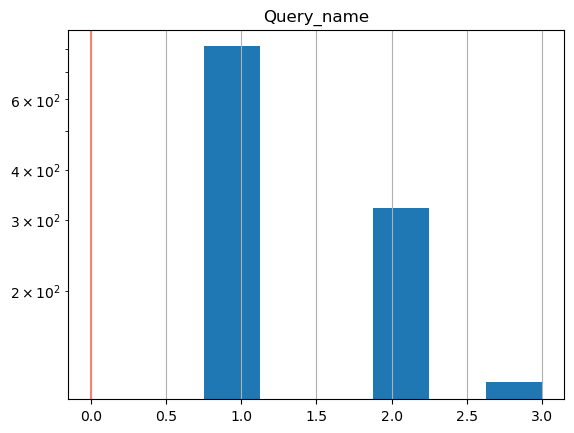

In [197]:
max_counts = df_list['Counts'].max()
vmin, vmax = (0, int(np.percentile(counts, 99.9)))
nbins = max_counts if max_counts < 10 else min(200, vmax - vmin)
df_bc_counts.hist(range=(vmin, vmax), bins = nbins)
plt.yscale("log")
DEPTH_THRESHOLD = 0
plt.axvline(DEPTH_THRESHOLD, color="salmon")

# plt.savefig(snakemake.output["barcode_hist"], dpi=150)

In [ ]:
### Get Barcode Histogram ###
snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv'
inpathlist = [snakemake_input]
# inpathlist = snakemake.input["tsv"]

barcode_dict = {}
for filepath in inpathlist:
    with open(filepath, "r") as infile:
        next(infile)
        for line in infile:
            data = line.split("\t")
            barcode_dict[data[0]] = data[1]

In [26]:
import csv
import numpy as np
import pickle as pkl

from matplotlib import pyplot as plt

In [30]:
def get_barcode_codebook(barcode_dict, final_barcode_idx):
    barcode_codebook = {}
    inv_barcode_codebook = {i: [] for i in range(len(final_barcode_idx))}
    for key, val in barcode_dict.items():
        if val in final_barcode_idx.keys():
            barcode_codebook[key] = final_barcode_idx[val]
            inv_barcode_codebook[final_barcode_idx[val]].append(key)
        else:
            barcode_codebook[key] = None
    return barcode_codebook, inv_barcode_codebook

In [31]:
### Get Barcode Histogram ###
snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv'
inpathlist = [snakemake_input]
# inpathlist = snakemake.input["tsv"]

barcode_dict = {}
for filepath in inpathlist:
    with open(filepath, "r") as infile:
        next(infile)
        for line in infile:
            data = line.split("\t")
            barcode_dict[data[0]] = data[1]

In [93]:
len(barcode_dict)

651

In [34]:
barcode_arr = np.array(list(barcode_dict.values()))
unique, counts = np.unique(barcode_arr, return_counts=True)
barcode_counts_dict = {unique[i]: counts[i] for i in range(len(unique))}

In [94]:
barcode_counts_dict

{'000000000000101101111010011011': 1,
 '000000000010001111010011011011': 1,
 '000000010011111011000010001010': 1,
 '000000011011011011101011110011': 2,
 '000000100101000111001010001001': 1,
 '000000100110111011011011000110': 1,
 '000000110111001101011010001010': 1,
 '000001000100001100010011001011': 2,
 '000001001010111010001010001101': 1,
 '000001001100011100101111010100': 1,
 '000001010110001100011100011100': 1,
 '000001010110101110011110000100': 1,
 '000001100011001010100010101001': 2,
 '000010001000001110001010000000': 1,
 '000010001100111000000101011001': 1,
 '000010010100100010010011101001': 1,
 '000010011000001100001000001001': 1,
 '000010100001001101001011110011': 1,
 '000010101001000011110101001010': 1,
 '000010101001000011110101001111': 1,
 '000010101001101010000101101110': 1,
 '000010101001111010000101101110': 1,
 '000010110110001110101001001100': 1,
 '000011001001100110110110100110': 1,
 '000011010011101110110010000101': 1,
 '000011011001100100000011110110': 1,
 '0000110110

In [ ]:
with open(snakemake.output["barcode_counts_dict"], "wb") as f:
    pkl.dump(barcode_counts_dict, f, pkl.HIGHEST_PROTOCOL)

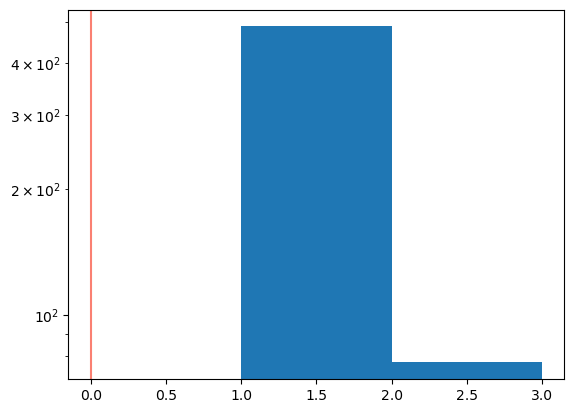

In [40]:
vmin, vmax = (0, int(np.percentile(counts, 99.9)))
nbins = min(200, vmax - vmin)

plt.hist(counts, range=(vmin, vmax), bins=nbins)
plt.yscale("log")
DEPTH_THRESHOLD = 0
plt.axvline(DEPTH_THRESHOLD, color="salmon")
# plt.axvline(snakemake.params["threshold"], color="salmon")
# plt.savefig(snakemake.output["barcode_hist"], dpi=150)

In [131]:
### Threshold Barcodes and Create Index ###

final_barcode_arr = unique[counts >= DEPTH_THRESHOLD]
final_barcode_idx = dict(zip(final_barcode_arr, range(len(final_barcode_arr))))
rev_final_barcode_idx = {val: key for key, val in final_barcode_idx.items()}
_, inv_barcode_codebook = get_barcode_codebook(barcode_dict, final_barcode_idx)

# inv_barcode_codebook = {str(key):str(",".join(val)) for key,val in inv_barcode_codebook.items()}
inv_barcode_codebook = [
    {"barcodeid": key, "readlist": val, "barcode": rev_final_barcode_idx[key]}
    for key, val in inv_barcode_codebook.items()
]

In [132]:
inv_barcode_codebook

[{'barcodeid': 0,
  'readlist': ['6ac60ad1-8191-455d-8a9e-017983411060 LP5HKG_01'],
  'barcode': '000000000000101101111010011011'},
 {'barcodeid': 1,
  'readlist': ['1a4ef5c7-2120-4f40-be47-5210ff81e5e0 LP5HKG_01'],
  'barcode': '000000000010001111010011011011'},
 {'barcodeid': 2,
  'readlist': ['af312c0e-3bed-437c-8b8b-fb0a5cd099c9 LP5HKG_01'],
  'barcode': '000000010011111011000010001010'},
 {'barcodeid': 3,
  'readlist': ['7eb6ddaf-6a64-4108-ad36-f1d225814515 LP5HKG_01',
   'dd52a2e9-304f-49b8-9e87-b985fca3c1a3 LP5HKG_01'],
  'barcode': '000000011011011011101011110011'},
 {'barcodeid': 4,
  'readlist': ['73cfd089-5f5f-44f3-ac68-df981878c73e LP5HKG_01'],
  'barcode': '000000100101000111001010001001'},
 {'barcodeid': 5,
  'readlist': ['aaababc8-e0f4-4d92-a25f-7e5a84f9f995 LP5HKG_01'],
  'barcode': '000000100110111011011011000110'},
 {'barcodeid': 6,
  'readlist': ['6dd258a8-f109-465b-b2ae-4e3744db7a31 LP5HKG_01'],
  'barcode': '000000110111001101011010001010'},
 {'barcodeid': 7,
  're

In [ ]:
keys = ["barcodeid", "readlist", "barcode"]
with open(snakemake.output["inv_barcode_codebook"], "w") as outfile:
    dict_writer = csv.DictWriter(outfile, keys, delimiter="\t")
    dict_writer.writeheader()
    dict_writer.writerows(inv_barcode_codebook)

In [27]:
with open('/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/barcode_counts_dict.pkl', 'rb') as f:
    x = pkl.load(f)

In [28]:
x

{'000000000000101101111010011011': 4,
 '000000000010001111010011011011': 3,
 '000000000110001001110011000000': 3,
 '000000000110101100100111101000': 1,
 '000000000111001110011011011010': 2,
 '000000001000100011100000101011': 1,
 '000000001000100011110101101011': 2,
 '000000001000100101011101100101': 2,
 '000000001101001001011000110000': 3,
 '000000010000010111000011101000': 1,
 '000000010000101110001011110001': 1,
 '000000010001010010100111001110': 4,
 '000000010011111011000010001010': 3,
 '000000011000001100011011000011': 5,
 '000000011001001011000100001011': 1,
 '000000011010001111111000011010': 1,
 '000000011011011011101011110011': 5,
 '000000011100101111101011010000': 4,
 '000000011111001011001110110110': 4,
 '000000100101000111001010001001': 6,
 '000000100110111011011011000110': 6,
 '000000101001000001100111101001': 3,
 '000000101001100100101001010010': 1,
 '000000110100001100011100011100': 1,
 '000000110110100011100001101011': 4,
 '000000110111001101011010001010': 4,
 '0000001101

In [29]:
print(1)

1


In [ ]:
ll